# Week 3 – Seoul Bike Sharing

A simple monthly-weather simulation. Run the cells **from top to bottom**. All averages and weather effects are calculated using training data only.

## 1. Import libraries

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load and check the data

Read the CSV, create timestamps, check missing values and duplicates, and prepare the model columns.

In [2]:
# 1. Load and check observations
csv = Path('../SeoulBikeData.csv')
if not csv.exists():
    csv = Path('SeoulBikeData.csv')
df = pd.read_csv(csv, encoding='latin1')
df['Timestamp'] = pd.to_datetime(df['Date'], dayfirst=True) + pd.to_timedelta(df['Hour'], unit='h')
print('Missing values:', df.isna().sum().sum())
print('Duplicate timestamps:', df['Timestamp'].duplicated().sum())

# Keep the columns used by our model, including shutdown days
weather = ['Temperature(°C)', 'Humidity(%)', 'Rainfall(mm)', 'Wind speed (m/s)']
cols = ['Timestamp', 'Hour', 'Functioning Day', 'Rented Bike Count'] + weather
df = df[cols].dropna().drop_duplicates('Timestamp').sort_values('Timestamp').copy()
df['Month'] = df['Timestamp'].dt.month
df['Day'] = df['Timestamp'].dt.date
print(df.head().to_string(index=False))

Missing values: 0
Duplicate timestamps: 0
          Timestamp  Hour Functioning Day  Rented Bike Count  Temperature(°C)  Humidity(%)  Rainfall(mm)  Wind speed (m/s)  Month        Day
2017-12-01 00:00:00     0             Yes                254             -5.2           37           0.0               2.2     12 2017-12-01
2017-12-01 01:00:00     1             Yes                204             -5.5           38           0.0               0.8     12 2017-12-01
2017-12-01 02:00:00     2             Yes                173             -6.0           39           0.0               1.0     12 2017-12-01
2017-12-01 03:00:00     3             Yes                107             -6.2           40           0.0               0.9     12 2017-12-01
2017-12-01 04:00:00     4             Yes                 78             -6.0           36           0.0               2.3     12 2017-12-01


## 3. Plot measured rentals

Show the first seven days of observed bicycle rentals.

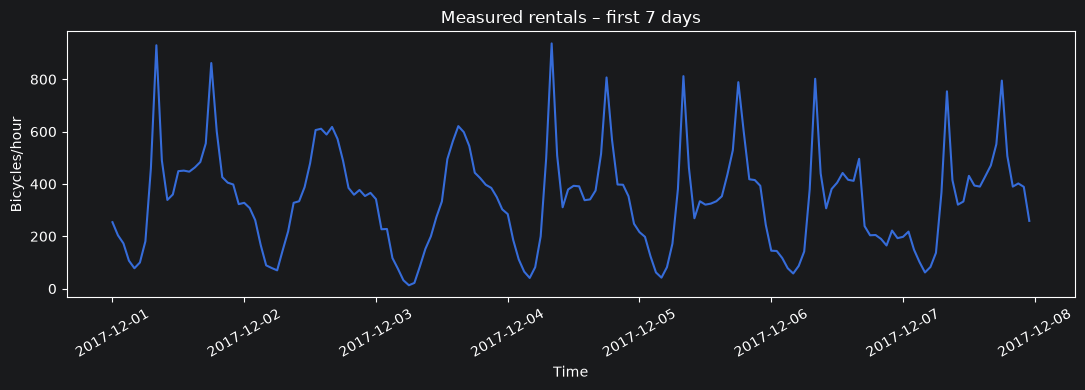

In [3]:
plt.figure(figsize=(11, 4))
plt.plot(df['Timestamp'].iloc[:168], df['Rented Bike Count'].iloc[:168])
plt.title('Measured rentals – first 7 days')
plt.xlabel('Time')
plt.ylabel('Bicycles/hour')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Split training and test data

Within each month, use approximately 80% of **complete days** for training and 20% for testing.

In [4]:
# 2. Split full days within each month (80% train, 20% test)
train_parts, test_parts = [], []
for month, group in df.groupby('Month'):
    days = sorted(group['Day'].unique())
    cutoff = int(len(days) * 0.8)
    train_parts.append(group[group['Day'].isin(days[:cutoff])])
    test_parts.append(group[group['Day'].isin(days[cutoff:])])
train = pd.concat(train_parts)
test = pd.concat(test_parts).copy()
print('Training rows:', len(train), '| Test rows:', len(test))

Training rows: 6864 | Test rows: 1896


## 5. Calculate monthly averages

Calculate monthly weather averages and month-hour rental averages using **training data only**.

In [5]:
# 3. Monthly average weather and month-hour average rentals
active = train[train['Functioning Day'] == 'Yes'].copy()
monthly_weather = train.groupby('Month')[weather].mean()
rental_average = active.groupby(['Month', 'Hour'])['Rented Bike Count'].mean()
print('Monthly weather averages:')
print(monthly_weather.round(2))

Monthly weather averages:
       Temperature(°C)  Humidity(%)  Rainfall(mm)  Wind speed (m/s)
Month                                                              
1                -2.52        49.92          0.01              1.78
2                -3.04        41.82          0.00              2.31
3                 6.57        58.54          0.09              1.94
4                12.22        55.99          0.23              2.04
5                17.34        64.75          0.38              1.71
6                22.91        58.63          0.09              1.72
7                26.85        69.06          0.31              1.43
8                30.00        60.48          0.06              1.71
9                22.24        62.96          0.12              1.59
10               14.23        59.05          0.18              1.46
11                8.53        58.56          0.14              1.41
12               -2.02        56.90          0.06              1.69


## 6. Calculate weather effects

Compare weather readings with their monthly means and estimate simple relative rental effects from training data.

In [6]:
# 4. Estimate simple weather effects from TRAINING observations
# Compare each observation with its month's average weather.
# Remove the usual month-hour rental pattern before calculating effects.
active['Baseline'] = [rental_average.loc[m, h] for m, h in zip(active['Month'], active['Hour'])]
active = active[active['Baseline'] > 0].copy()
active['Relative Rentals'] = active['Rented Bike Count'] / active['Baseline']

weather_effects = {}
for column in weather:
    # True = at or above monthly average; False = below monthly average
    above = active[column] >= active['Month'].map(monthly_weather[column])
    averages = active.groupby(['Month', above])['Relative Rentals'].mean()
    for month in monthly_weather.index:
        for is_above in [False, True]:
            # Missing groups have no estimated effect
            weather_effects[(month, column, is_above)] = averages.get((month, is_above), 1.0)

## 7. Run the simulation

Use each test row’s hour, month, weather and service status. The actual test rental count is not used to calculate the prediction.

In [9]:
# 5. Simulate each TEST row (without reading its actual rental count)
def simulate(row):
    if row['Functioning Day'] == 'No':
        return 0
    month, hour = row['Month'], row['Hour']
    estimate = rental_average.loc[month, hour]
    for column in weather:
        is_above = row[column] >= monthly_weather.loc[month, column]
        estimate *= weather_effects[(month, column, is_above)]
    return round(max(0, estimate))

test['Simulated Rented Bike Count'] = test.apply(simulate, axis=1)
print(test[['Timestamp', 'Rented Bike Count', 'Simulated Rented Bike Count']].head(20))

               Timestamp  Rented Bike Count  Simulated Rented Bike Count
1320 2018-01-25 00:00:00                 78                          136
1321 2018-01-25 01:00:00                 68                          128
1322 2018-01-25 02:00:00                 60                          105
1323 2018-01-25 03:00:00                 32                           60
1324 2018-01-25 04:00:00                 22                           40
1325 2018-01-25 05:00:00                 34                           44
1326 2018-01-25 06:00:00                 71                           82
1327 2018-01-25 07:00:00                165                          178
1328 2018-01-25 08:00:00                349                          361
1329 2018-01-25 09:00:00                187                          221
1330 2018-01-25 10:00:00                105                          157
1331 2018-01-25 11:00:00                122                          191
1332 2018-01-25 12:00:00                142        

## 8. Compare simulated and measured rentals

Plot both series at the same timestamps and calculate mean absolute error (MAE).

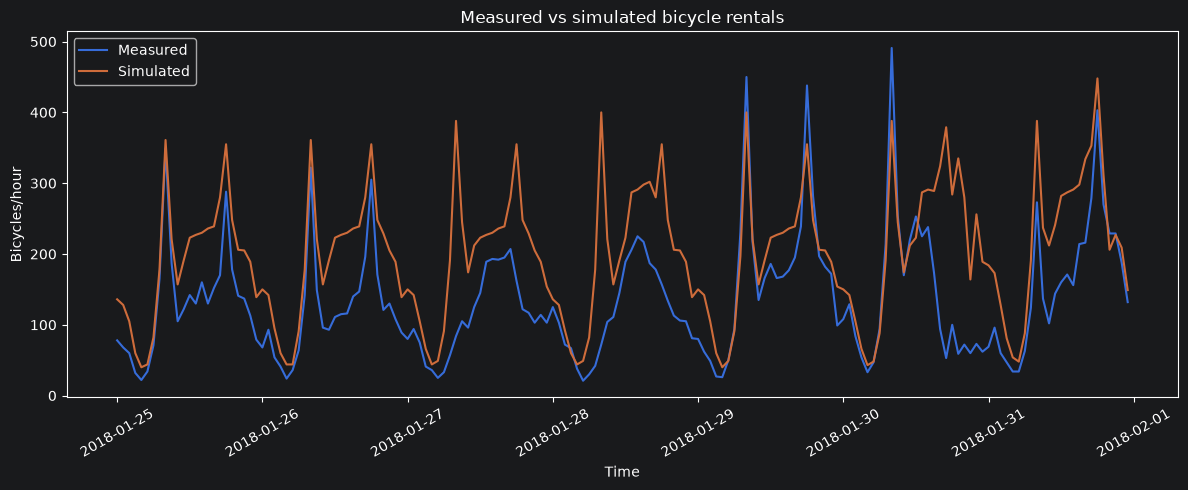

Mean Absolute Error: 216.0 bicycles/hour


In [10]:
# 6. Compare measured and simulated rentals on the same timeline
# Display one test week (the first test month) to avoid long gaps between months
first_month = test['Month'].iloc[0]
week = test[test['Month'] == first_month].head(168)
plt.figure(figsize=(12, 5))
plt.plot(week['Timestamp'], week['Rented Bike Count'], label='Measured')
plt.plot(week['Timestamp'], week['Simulated Rented Bike Count'], label='Simulated')
plt.title('Measured vs simulated bicycle rentals')
plt.xlabel('Time')
plt.ylabel('Bicycles/hour')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

mae = (test['Rented Bike Count'] - test['Simulated Rented Bike Count']).abs().mean()
print(f'Mean Absolute Error: {mae:.1f} bicycles/hour')

## Discussion and Week 4 preparation

The simulated and measured series can differ because the model uses averages, weather factors may overlap, and holidays or other influences are omitted. No calibration or automatic synchronization is implemented.

1. **Synchronization variable:** `Rented Bike Count` (bicycles/hour), a proxy for demand when service is available.
2. **Update frequency:** Hourly, matching the dataset.
3. **Next time step:** In a future dynamic version, update the estimated demand state with the latest rental observation, then use next-hour weather inputs to calculate the next state and output. This is **not implemented**. Zero rentals during a shutdown do not mean zero potential demand.

**Validation limitation:** Testing held-out days within known months is not the same as forecasting an unseen future month.